In [14]:
import os
import json
import random
import gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from scipy.ndimage import (
    binary_dilation,
    binary_erosion,
    distance_transform_edt
)

from scipy.stats import wilcoxon
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras import mixed_precision

print("TensorFlow:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [16]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

mixed_precision.set_global_policy("mixed_float16")

TARGET_SHAPE = (128, 128, 128)

BATCH_SIZE = 1

LEARNING_RATE = 2e-5

DROPOUT = 0.20

TAU = 0.50

EPSILON = 0.10

DILATION_KERNEL = 3

SMOKE_TEST = False

EPOCHS = 150

In [17]:
WORK_ROOT = Path(
    "/kaggle/working/cps_lcbts"
)

PREP_ROOT = (
    WORK_ROOT /
    "preprocessed"
)

PROB_ROOT = (
    WORK_ROOT /
    "wt_probabilities"
)

MODEL_ROOT = (
    WORK_ROOT /
    "models"
)

LOG_ROOT = (
    WORK_ROOT /
    "logs"
)

RESULT_ROOT = (
    WORK_ROOT /
    "results"
)

FIG_ROOT = (
    WORK_ROOT /
    "figures"
)

for folder in [
    WORK_ROOT,
    PREP_ROOT,
    PROB_ROOT,
    MODEL_ROOT,
    LOG_ROOT,
    RESULT_ROOT,
    FIG_ROOT
]:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Mixed precision:", mixed_precision.global_policy())
print("Epochs:", EPOCHS)
print("WORK_ROOT:", WORK_ROOT)

Mixed precision: <DTypePolicy "mixed_float16">
Epochs: 150
WORK_ROOT: /kaggle/working/cps_lcbts


In [19]:
training_root = Path(
    "/kaggle/input/datasets/awsaf49/"
    "brats20-dataset-training-validation/"
    "BraTS2020_TrainingData/"
    "MICCAI_BraTS2020_TrainingData"
)

print(
    "Training root exists:",
    training_root.exists()
)

Training root exists: True


In [20]:
case_dirs = sorted([
    p for p in training_root.iterdir()
    if (
        p.is_dir()
        and
        p.name.startswith(
            "BraTS20_Training_"
        )
    )
])

print(
    "Training patient folders found:",
    len(case_dirs)
)

print(
    "First:",
    case_dirs[0].name
)

print(
    "Last:",
    case_dirs[-1].name
)

Training patient folders found: 369
First: BraTS20_Training_001
Last: BraTS20_Training_369


In [59]:
def find_modality_file(
    case_dir,
    suffix
):

    case_dir = Path(
        case_dir
    )

    standard_matches = (
        list(
            case_dir.glob(
                f"*_{suffix}.nii"
            )
        )
        +
        list(
            case_dir.glob(
                f"*_{suffix}.nii.gz"
            )
        )
    )

    if len(
        standard_matches
    ) == 1:

        return (
            standard_matches[0]
        )

    if suffix == "seg":

        alternative_matches = (

            list(
                case_dir.glob(
                    "*Segm.nii"
                )
            )

            +

            list(
                case_dir.glob(
                    "*Segm.nii.gz"
                )
            )

            +

            list(
                case_dir.glob(
                    "*segm.nii"
                )
            )

            +

            list(
                case_dir.glob(
                    "*segm.nii.gz"
                )
            )
        )

        if len(
            alternative_matches
        ) == 1:

            return (
                alternative_matches[0]
            )

    raise FileNotFoundError(
        f"Could not find "
        f"{suffix} in "
        f"{case_dir}"
    )

In [22]:
problem_cases = []

for case in case_dirs:

    for suffix in [
        "t1",
        "t1ce",
        "t2",
        "flair",
        "seg"
    ]:

        try:

            _ = find_modality_file(
                case,
                suffix
            )

        except Exception as e:

            problem_cases.append(
                (
                    case.name,
                    suffix,
                    str(e)
                )
            )

print(
    "Total cases:",
    len(case_dirs)
)

print(
    "Problem files:",
    len(problem_cases)
)

if problem_cases:
    print(
        problem_cases[:10]
    )

Total cases: 369
Problem files: 0


In [23]:
split_file = (
    WORK_ROOT /
    "splits.json"
)

In [24]:
if split_file.exists():

    print(
        "Existing split found."
    )

    with open(
        split_file,
        "r"
    ) as f:

        splits = json.load(f)

    train_paths = np.array(
        splits["train"]
    )

    val_paths = np.array(
        splits["val"]
    )

    test_paths = np.array(
        splits["test"]
    )

else:

    print(
        "No saved split found."
    )

    print(
        "Recreating deterministic "
        "SEED=42 split."
    )

    all_case_paths = np.array([
        str(p)
        for p in case_dirs
    ])

    train_paths, temp_paths = (
        train_test_split(
            all_case_paths,
            test_size=0.20,
            random_state=SEED,
            shuffle=True
        )
    )

    val_paths, test_paths = (
        train_test_split(
            temp_paths,
            test_size=0.50,
            random_state=SEED,
            shuffle=True
        )
    )

    splits = {

        "train":
            train_paths.tolist(),

        "val":
            val_paths.tolist(),

        "test":
            test_paths.tolist()
    }

    with open(
        split_file,
        "w"
    ) as f:

        json.dump(
            splits,
            f,
            indent=2
        )

Existing split found.


In [25]:
print(
    "Train:",
    len(train_paths)
)

print(
    "Validation:",
    len(val_paths)
)

print(
    "Test:",
    len(test_paths)
)

print(
    "Train/Val overlap:",
    len(
        set(train_paths)
        &
        set(val_paths)
    )
)

print(
    "Train/Test overlap:",
    len(
        set(train_paths)
        &
        set(test_paths)
    )
)

print(
    "Val/Test overlap:",
    len(
        set(val_paths)
        &
        set(test_paths)
    )
)

Train: 295
Validation: 37
Test: 37
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [26]:
sample_case = Path(
    train_paths[0]
)

raw = {}

for modality in [
    "t1",
    "t1ce",
    "t2",
    "flair",
    "seg"
]:

    raw[
        modality
    ] = nib.load(
        find_modality_file(
            sample_case,
            modality
        )
    ).get_fdata()

print(
    "Patient:",
    sample_case.name
)

for name, volume in raw.items():

    print(
        name,
        volume.shape
    )

print(
    "Seg labels:",
    np.unique(
        raw["seg"]
    )
)

Patient: BraTS20_Training_345
t1 (240, 240, 155)
t1ce (240, 240, 155)
t2 (240, 240, 155)
flair (240, 240, 155)
seg (240, 240, 155)
Seg labels: [0. 1. 2. 4.]


In [27]:
TARGET_SHAPE = (128, 128, 128)

MODALITIES = [
    "t1",
    "t1ce",
    "t2",
    "flair"
]

In [28]:
def crop_brats(volume, target_shape=(128, 128, 128)):

    target_x, target_y, target_z = target_shape

    x, y, z = volume.shape

    start_x = (x - target_x) // 2
    start_y = (y - target_y) // 2

    start_z = 15

    cropped = volume[
        start_x:start_x + target_x,
        start_y:start_y + target_y,
        start_z:start_z + target_z
    ]

    if cropped.shape != target_shape:
        raise ValueError(
            f"Unexpected crop shape {cropped.shape}"
        )

    return cropped

In [29]:
def zscore_normalize(volume, eps=1e-8):

    volume = volume.astype(np.float32)

    mean = np.mean(volume)
    std = np.std(volume)

    normalized = (
        volume - mean
    ) / (std + eps)

    return normalized

In [30]:
def create_binary_masks(seg):

    wt = (seg > 0).astype(np.uint8)

    tc = np.isin(
        seg,
        [1, 4]
    ).astype(np.uint8)

    et = (
        seg == 4
    ).astype(np.uint8)

    return wt, tc, et

In [31]:
def preprocess_patient(case_dir):

    case_dir = Path(case_dir)

    channels = []

    for modality in MODALITIES:

        file_path = find_modality_file(
            case_dir,
            modality
        )

        volume = nib.load(
            file_path
        ).get_fdata(
            dtype=np.float32
        )

        volume = crop_brats(volume)

        volume = zscore_normalize(
            volume
        )

        channels.append(volume)

    X = np.stack(
        channels,
        axis=-1
    ).astype(np.float32)

    seg_path = find_modality_file(
        case_dir,
        "seg"
    )

    seg = nib.load(
        seg_path
    ).get_fdata()

    seg = crop_brats(seg)

    seg = seg.astype(np.uint8)

    wt, tc, et = create_binary_masks(seg)

    return X, wt, tc, et

In [32]:
X_test, wt_test, tc_test, et_test = (
    preprocess_patient(
        train_paths[0]
    )
)

print(
    "MRI:",
    X_test.shape
)

print(
    "WT:",
    wt_test.shape
)

print(
    "TC:",
    tc_test.shape
)

print(
    "ET:",
    et_test.shape
)

print(
    "MRI mean:",
    X_test.mean()
)

print(
    "MRI std:",
    X_test.std()
)

MRI: (128, 128, 128, 4)
WT: (128, 128, 128)
TC: (128, 128, 128)
ET: (128, 128, 128)
MRI mean: 5.122274e-08
MRI std: 1.0000014


In [33]:
def preprocess_and_save(case_dir):

    case_dir = Path(case_dir)

    output_file = (
        PREP_ROOT /
        f"{case_dir.name}.npz"
    )

    if output_file.exists():
        return output_file

    X, wt, tc, et = preprocess_patient(
        case_dir
    )

    np.savez_compressed(
        output_file,

        X=X.astype(np.float16),

        y_wt=wt.astype(np.uint8),
        y_tc=tc.astype(np.uint8),
        y_et=et.astype(np.uint8)
    )

    return output_file

In [ ]:
print("Starting preprocessing...")

for i, case in enumerate(
    case_dirs,
    start=1
):

    preprocess_and_save(case)

    if i % 10 == 0 or i == len(case_dirs):
        print(
            f"Processed {i}/{len(case_dirs)}"
        )

print("Preprocessing complete.")

Starting preprocessing...
Processed 10/369
Processed 20/369
Processed 30/369
Processed 40/369
Processed 50/369
Processed 60/369
Processed 70/369


In [103]:
def preprocessed_path(
    original_case_path
):

    case_name = Path(
        original_case_path
    ).name

    return str(
        PREP_ROOT /
        f"{case_name}.npz"
    )

In [104]:
split_npz = {

    "train": [
        preprocessed_path(p)
        for p in train_paths
    ],

    "val": [
        preprocessed_path(p)
        for p in val_paths
    ],

    "test": [
        preprocessed_path(p)
        for p in test_paths
    ]
}

print(
    "Train:",
    len(split_npz["train"])
)

print(
    "Validation:",
    len(split_npz["val"])
)

print(
    "Test:",
    len(split_npz["test"])
)

Train: 295
Validation: 37
Test: 37


In [105]:
TARGET_INDEX = {
    "wt": 0,
    "tc": 1,
    "et": 2
}

In [106]:
def load_plain_numpy(
    path_bytes,
    target_index
):

    path = path_bytes.decode(
        "utf-8"
    )

    with np.load(path) as data:

        X = data[
            "X"
        ].astype(np.float32)

        target_keys = [
            "y_wt",
            "y_tc",
            "y_et"
        ]

        y = data[
            target_keys[
                int(target_index)
            ]
        ].astype(np.float32)

    y = y[..., None]

    return X, y

In [107]:
def make_plain_dataset(
    files,
    target="wt",
    training=False
):

    target_index = (
        TARGET_INDEX[target]
    )

    dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            files
        )
    )

    if training:

        dataset = dataset.shuffle(
            len(files),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    def mapper(path):

        X, y = tf.numpy_function(

            lambda p:
                load_plain_numpy(
                    p,
                    target_index
                ),

            [path],

            [
                tf.float32,
                tf.float32
            ]
        )

        X.set_shape(
            (
                128,
                128,
                128,
                4
            )
        )

        y.set_shape(
            (
                128,
                128,
                128,
                1
            )
        )

        return X, y

    dataset = dataset.map(
        mapper,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(
        BATCH_SIZE
    )

    # Keep low because each 3D case is large
    dataset = dataset.prefetch(1)

    return dataset

In [108]:
SMOOTH = 1.0

In [109]:
def dice_coefficient(
    y_true,
    y_pred
):

    y_true = tf.cast(
        y_true,
        tf.float32
    )

    y_pred = tf.cast(
        y_pred,
        tf.float32
    )

    axes = (
        1,
        2,
        3,
        4
    )

    intersection = tf.reduce_sum(
        y_true * y_pred,
        axis=axes
    )

    denominator = (

        tf.reduce_sum(
            tf.square(y_true),
            axis=axes
        )

        +

        tf.reduce_sum(
            tf.square(y_pred),
            axis=axes
        )
    )

    dice = (

        2.0 * intersection
        + SMOOTH

    ) / (

        denominator
        + SMOOTH
    )

    return tf.reduce_mean(
        dice
    )

In [110]:
def dice_loss(
    y_true,
    y_pred
):

    return (
        1.0
        -
        dice_coefficient(
            y_true,
            y_pred
        )
    )

In [111]:
class InstanceNormalization(
    tf.keras.layers.Layer
):

    def __init__(
        self,
        epsilon=1e-5,
        **kwargs
    ):

        super().__init__(
            **kwargs
        )

        self.epsilon = epsilon

    def build(
        self,
        input_shape
    ):

        channels = int(
            input_shape[-1]
        )

        self.gamma = self.add_weight(
            name="gamma",
            shape=(channels,),
            initializer="ones",
            trainable=True
        )

        self.beta = self.add_weight(
            name="beta",
            shape=(channels,),
            initializer="zeros",
            trainable=True
        )

    def call(
        self,
        inputs
    ):

        x = tf.cast(
            inputs,
            tf.float32
        )

        mean, variance = tf.nn.moments(
            x,
            axes=[
                1,
                2,
                3
            ],
            keepdims=True
        )

        x = (
            x - mean
        ) / tf.sqrt(
            variance
            +
            self.epsilon
        )

        x = (
            x * self.gamma
            +
            self.beta
        )

        return tf.cast(
            x,
            inputs.dtype
        )

In [112]:
def conv_block(
    x,
    filters,
    kernel_size=3,
    name="conv"
):

    x = layers.Conv3D(
        filters,
        kernel_size,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_conv"
    )(x)

    x = InstanceNormalization(
        name=f"{name}_in"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01,
        name=f"{name}_act"
    )(x)

    return x

In [115]:
def encoder_block(
    x,
    filters,
    pooling=True,
    name="EB"
):

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_1"
    )

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_2"
    )

    skip = x

    if pooling:

        x = layers.MaxPool3D(
            pool_size=2,
            name=f"{name}_pool"
        )(x)

        x = layers.Dropout(
            DROPOUT,
            name=f"{name}_dropout"
        )(x)

    return x, skip

In [116]:
def lateral_block(
    x,
    filters=64,
    name="LB"
):

    x = layers.Conv3D(
        filters,
        kernel_size=1,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_conv"
    )(x)

    x = InstanceNormalization(
        name=f"{name}_in"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    return x

In [117]:
def decoder_block(
    x,
    filters=64,
    name="DB"
):

    x = layers.Conv3DTranspose(
        filters,
        kernel_size=2,
        strides=2,
        padding="same",
        kernel_initializer="he_normal",
        name=f"{name}_up"
    )(x)

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_conv"
    )

    return x

In [118]:
def merge_block(
    lateral,
    decoder,
    filters=64,
    name="MB"
):

    x = layers.Add(
        name=f"{name}_add"
    )([
        lateral,
        decoder
    ])

    x = layers.Dropout(
        DROPOUT,
        name=f"{name}_dropout"
    )(x)

    x = conv_block(
        x,
        filters,
        3,
        name=f"{name}_conv"
    )

    return x

In [119]:
def build_lcbts_subnetwork(
    name="LCBTS"
):

    inputs = keras.Input(
        shape=(
            128,
            128,
            128,
            4
        ),
        name="input"
    )

    # Encoder
    x, skip1 = encoder_block(
        inputs,
        32,
        True,
        "EB1"
    )

    x, skip2 = encoder_block(
        x,
        64,
        True,
        "EB2"
    )

    x, skip3 = encoder_block(
        x,
        64,
        True,
        "EB3"
    )

    x, _ = encoder_block(
        x,
        64,
        False,
        "EB4"
    )

    # Decoder level 3
    lateral3 = lateral_block(
        skip3,
        64,
        "LB3"
    )

    decoder3 = decoder_block(
        x,
        64,
        "DB3"
    )

    x = merge_block(
        lateral3,
        decoder3,
        64,
        "MB3"
    )

    # Decoder level 2
    lateral2 = lateral_block(
        skip2,
        64,
        "LB2"
    )

    decoder2 = decoder_block(
        x,
        64,
        "DB2"
    )

    x = merge_block(
        lateral2,
        decoder2,
        64,
        "MB2"
    )

    # Decoder level 1
    lateral1 = lateral_block(
        skip1,
        64,
        "LB1"
    )

    decoder1 = decoder_block(
        x,
        64,
        "DB1"
    )

    x = merge_block(
        lateral1,
        decoder1,
        64,
        "MB1"
    )

    # Final feature block
    x = layers.Conv3D(
        64,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    x = layers.Conv3D(
        32,
        3,
        padding="same",
        kernel_initializer="he_normal"
    )(x)

    x = layers.LeakyReLU(
        negative_slope=0.01
    )(x)

    outputs = layers.Conv3D(
        1,
        kernel_size=1,
        activation="sigmoid",
        dtype="float32",
        name="prediction"
    )(x)

    return keras.Model(
        inputs,
        outputs,
        name=name
    )

In [120]:
test_model = build_lcbts_subnetwork()

print(
    "Parameters:",
    test_model.count_params()
)

test_model.summary()

Parameters: 1580737


Model: "LCBTS"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input (InputLayer)  │ (None, 128, 128,  │          0 │ -                 │
│                     │ 128, 4)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_1_conv (Conv3D) │ (None, 128, 128,  │      3,488 │ input[0][0]       │
│                     │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_1_in            │ (None, 128, 128,  │         64 │ EB1_1_conv[0][0]  │
│ (InstanceNormaliza… │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_1_act           │ (None, 128, 128,  │          0 │ EB1_1_in[0][0]    │
│ (LeakyReLU)         │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_2_conv (Conv3D) │ (None, 128, 128,  │     27,680 │ EB1_1_act[0][0]   │
│                     │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_2_in            │ (None, 128, 128,  │         64 │ EB1_2_conv[0][0]  │
│ (InstanceNormaliza… │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_2_act           │ (None, 128, 128,  │          0 │ EB1_2_in[0][0]    │
│ (LeakyReLU)         │ 128, 32)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_pool            │ (None, 64, 64,    │          0 │ EB1_2_act[0][0]   │
│ (MaxPooling3D)      │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB1_dropout         │ (None, 64, 64,    │          0 │ EB1_pool[0][0]    │
│ (Dropout)           │ 64, 32)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_1_conv (Conv3D) │ (None, 64, 64,    │     55,360 │ EB1_dropout[0][0] │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_1_in            │ (None, 64, 64,    │        128 │ EB2_1_conv[0][0]  │
│ (InstanceNormaliza… │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_1_act           │ (None, 64, 64,    │          0 │ EB2_1_in[0][0]    │
│ (LeakyReLU)         │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_2_conv (Conv3D) │ (None, 64, 64,    │    110,656 │ EB2_1_act[0][0]   │
│                     │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_2_in            │ (None, 64, 64,    │        128 │ EB2_2_conv[0][0]  │
│ (InstanceNormaliza… │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_2_act           │ (None, 64, 64,    │          0 │ EB2_2_in[0][0]    │
│ (LeakyReLU)         │ 64, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_pool            │ (None, 32, 32,    │          0 │ EB2_2_act[0][0]   │
│ (MaxPooling3D)      │ 32, 64)           │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ EB2_dropout         │ (None, 32, 32,    │          0 │ EB2_pool[0][0]  

 Total params: 1,580,737 (6.03 MB)

 Trainable params: 1,580,737 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

In [121]:
del test_model

tf.keras.backend.clear_session()

gc.collect()

0

In [123]:
def compile_model(
    model
):

    optimizer = keras.optimizers.Adam(
        learning_rate=LEARNING_RATE,
        beta_1=0.9,
        beta_2=0.999
    )

    model.compile(
        optimizer=optimizer,
        loss=dice_loss,
        metrics=[
            dice_coefficient
        ]
    )

    return model

In [124]:
def train_model(
    model,
    train_dataset,
    val_dataset,
    run_name,
    epochs
):

    model = compile_model(
        model
    )

    best_path = (
        MODEL_ROOT /
        f"{run_name}_best.keras"
    )

    last_path = (
        MODEL_ROOT /
        f"{run_name}_last.keras"
    )

    csv_path = (
        LOG_ROOT /
        f"{run_name}.csv"
    )

    callbacks = [

        keras.callbacks.ModelCheckpoint(
            best_path,
            monitor="val_dice_coefficient",
            mode="max",
            save_best_only=True,
            verbose=1
        ),

        keras.callbacks.ModelCheckpoint(
            last_path,
            save_best_only=False,
            verbose=0
        ),

        keras.callbacks.CSVLogger(
            csv_path
        ),

        keras.callbacks.TerminateOnNaN()
    ]

    history = model.fit(
        train_dataset,
        validation_data=val_dataset,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1
    )

    return model, history

In [125]:
wt_train_ds = make_plain_dataset(
    split_npz["train"],
    target="wt",
    training=True
)

wt_val_ds = make_plain_dataset(
    split_npz["val"],
    target="wt",
    training=False
)

print(
    "WT train/validation datasets created."
)

WT train/validation datasets created.


In [134]:
from tensorflow.keras import mixed_precision

mixed_precision.set_global_policy("mixed_float16")

print("Global policy:")
print(mixed_precision.global_policy())

Global policy:
<DTypePolicy "mixed_float16">


In [135]:
tf.keras.utils.set_random_seed(
    SEED
)

wt_model = build_lcbts_subnetwork(
    name="WT_LCBTS"
)

print(
    "WT parameters:",
    wt_model.count_params()
)

WT parameters: 1580737


In [1]:
wt_model, wt_history = train_model(
    wt_model,
    wt_train_ds,
    wt_val_ds,
    run_name="wt",
    epochs=EPOCHS
)

Epoch 1/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.7213 | dice: 0.2787 | val_loss: 0.7204 | val_dice: 0.2796
✓ New best val_dice: 0.2796 — saved /kaggle/working/cps_lcbts/models/wt_best.keras

Epoch 2/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.6794 | dice: 0.3206 | val_loss: 0.6792 | val_dice: 0.3208
✓ New best val_dice: 0.3208 — saved /kaggle/working/cps_lcbts/models/wt_best.keras

Epoch 3/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.6381 | dice: 0.3619 | val_loss: 0.6435 | val_dice: 0.3565
✓ New best val_dice: 0.3565 — saved /kaggle/working/cps_lcbts/models/wt_best.keras

Epoch 4/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.5992 | dice: 0.4008 | val_loss: 0.6053 | val_dice: 0.3947
✓ New best val_dice: 0.3947 — saved /kaggle/working/cps_lcbts/models/wt_best.keras

Epoch 5/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.5667 | dice: 0.4333 | val_loss: 0.5715 | val_dice: 0.4285
✓ New best val_dice: 0.4285 — saved /kaggle/working/cps_lcbts/models/wt_best.keras

Epoch 6/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss

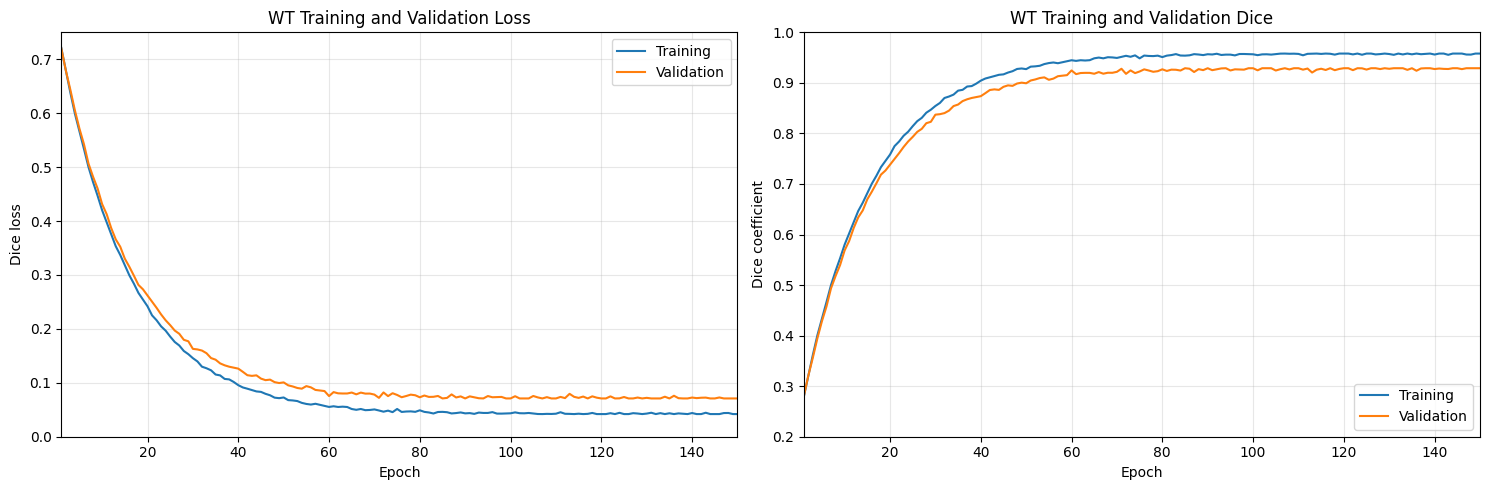

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path


wt_log_path = LOG_ROOT / "wt.csv"

if wt_log_path.exists():

    wt_log = pd.read_csv(wt_log_path)

    epochs = wt_log["epoch"].to_numpy() + 1

    train_loss = wt_log["loss"].to_numpy()
    val_loss = wt_log["val_loss"].to_numpy()

    train_dice = wt_log["dice_coefficient"].to_numpy()
    val_dice = wt_log["val_dice_coefficient"].to_numpy()

else:

    # Fallback: use the in-memory Keras history
    epochs = range(
        1,
        len(wt_history.history["loss"]) + 1
    )

    train_loss = wt_history.history["loss"]
    val_loss = wt_history.history["val_loss"]

    train_dice = wt_history.history["dice_coefficient"]
    val_dice = wt_history.history["val_dice_coefficient"]


fig, axes = plt.subplots(
    1,
    2,
    figsize=(16, 5)
)

axes[0].plot(
    epochs,
    train_loss,
    label="Training"
)

axes[0].plot(
    epochs,
    val_loss,
    label="Validation"
)

axes[0].set_title(
    "WT Training and Validation Loss"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Dice Loss"
)

axes[0].legend()

axes[0].grid(
    True,
    alpha=0.3
)


axes[1].plot(
    epochs,
    train_dice,
    label="Training"
)

axes[1].plot(
    epochs,
    val_dice,
    label="Validation"
)

axes[1].set_title(
    "WT Training and Validation Dice"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Dice Coefficient"
)

axes[1].legend()

axes[1].grid(
    True,
    alpha=0.3
)


plt.tight_layout()

FIG_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

figure_path = (
    FIG_ROOT /
    "WT_training_validation_curves.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Figure saved to:",
    figure_path
)

In [104]:
def make_guided_volume(
    X,
    p_wt,
    mode="hard",
    tau=0.5,
    epsilon=0.10,
    dilation_kernel=3
):

    X = X.astype(
        np.float32
    )

    p_wt = p_wt.astype(
        np.float32
    )

    hard_mask = (
        p_wt >= tau
    )

    if mode == "hard":

        guidance = (
            hard_mask.astype(
                np.float32
            )
        )

    elif mode == "soft":

        guidance = (
            epsilon
            +
            (1.0 - epsilon)
            *
            p_wt
        )

    elif mode == "dilation":

        structure = np.ones(
            (
                dilation_kernel,
                dilation_kernel,
                dilation_kernel
            ),
            dtype=bool
        )

        dilated = binary_dilation(
            hard_mask,
            structure=structure
        )

        guidance = (
            dilated.astype(
                np.float32
            )
        )

    elif mode == "proposed":

        structure = np.ones(
            (
                dilation_kernel,
                dilation_kernel,
                dilation_kernel
            ),
            dtype=bool
        )

        dilated = binary_dilation(
            hard_mask,
            structure=structure
        )

        p_safe = np.maximum(
            p_wt,
            tau *
            dilated.astype(
                np.float32
            )
        )

        guidance = (
            epsilon
            +
            (1.0 - epsilon)
            *
            p_safe
        )

    else:

        raise ValueError(
            f"Unknown mode: {mode}"
        )

    guided_X = (
        X *
        guidance[..., None]
    )

    return guided_X

In [105]:
def load_guided_numpy(
    path_bytes,
    target_index,
    mode_bytes
):

    path = path_bytes.decode(
        "utf-8"
    )

    mode = mode_bytes.decode(
        "utf-8"
    )

    with np.load(path) as data:

        X = data[
            "X"
        ].astype(np.float32)

        target_keys = [
            "y_wt",
            "y_tc",
            "y_et"
        ]

        y = data[
            target_keys[
                int(target_index)
            ]
        ].astype(np.float32)

    with np.load(
        wt_probability_path(path)
    ) as probability_data:

        p_wt = probability_data[
            "p_wt"
        ].astype(np.float32)

    guided_X = make_guided_volume(
        X,
        p_wt,
        mode=mode
    )

    y = y[..., None]

    return guided_X, y

In [106]:
def make_guided_dataset(
    files,
    target,
    mode,
    training=False
):

    target_index = (
        TARGET_INDEX[target]
    )

    dataset = (
        tf.data.Dataset
        .from_tensor_slices(
            files
        )
    )

    if training:

        dataset = dataset.shuffle(
            len(files),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    mode_tensor = tf.constant(
        mode
    )

    def mapper(path):

        X, y = tf.numpy_function(
            lambda p, m:
                load_guided_numpy(
                    p,
                    target_index,
                    m
                ),
            [
                path,
                mode_tensor
            ],
            [
                tf.float32,
                tf.float32
            ]
        )

        X.set_shape(
            (
                128,
                128,
                128,
                4
            )
        )

        y.set_shape(
            (
                128,
                128,
                128,
                1
            )
        )

        return X, y

    dataset = dataset.map(
        mapper,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(1)

    dataset = dataset.prefetch(1)

    return dataset

In [112]:
prop_tc_train = make_guided_dataset(
    split_npz["train"],
    target="tc",
    mode="proposed",
    training=True
)

prop_tc_val = make_guided_dataset(
    split_npz["val"],
    target="tc",
    mode="proposed",
    training=False
)

In [3]:
tf.keras.utils.set_random_seed(
    SEED + 101
)

prop_tc_model = (
    build_lcbts_subnetwork(
        "Proposed_TC"
    )
)

prop_tc_model, prop_tc_history = train_model(
    prop_tc_model,
    prop_tc_train,
    prop_tc_val,
    "proposed_tc",
    EPOCHS
)

Epoch 1/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8685 | dice: 0.1315 | val_loss: 0.8212 | val_dice: 0.1788
✓ New best val_dice: 0.1788 — saved /kaggle/working/cps_lcbts/models/proposed_tc_best.keras

Epoch 2/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8265 | dice: 0.1735 | val_loss: 0.7822 | val_dice: 0.2178
✓ New best val_dice: 0.2178 — saved /kaggle/working/cps_lcbts/models/proposed_tc_best.keras

Epoch 3/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.7826 | dice: 0.2174 | val_loss: 0.7509 | val_dice: 0.2491
✓ New best val_dice: 0.2491 — saved /kaggle/working/cps_lcbts/models/proposed_tc_best.keras

Epoch 4/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.7407 | dice: 0.2593 | val_loss: 0.7118 | val_dice: 0.2882
✓ New best val_dice: 0.2882 — saved /kaggle/working/cps_lcbts/models/proposed_tc_best.keras

Epoch 5/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.7088 | dice: 0.2912 | val_loss: 0.6788 | val_dice: 0.3212
✓ New best val_dice: 0.3212 — saved /kaggle/working/cps_lcbts/models/proposed_tc_best.keras



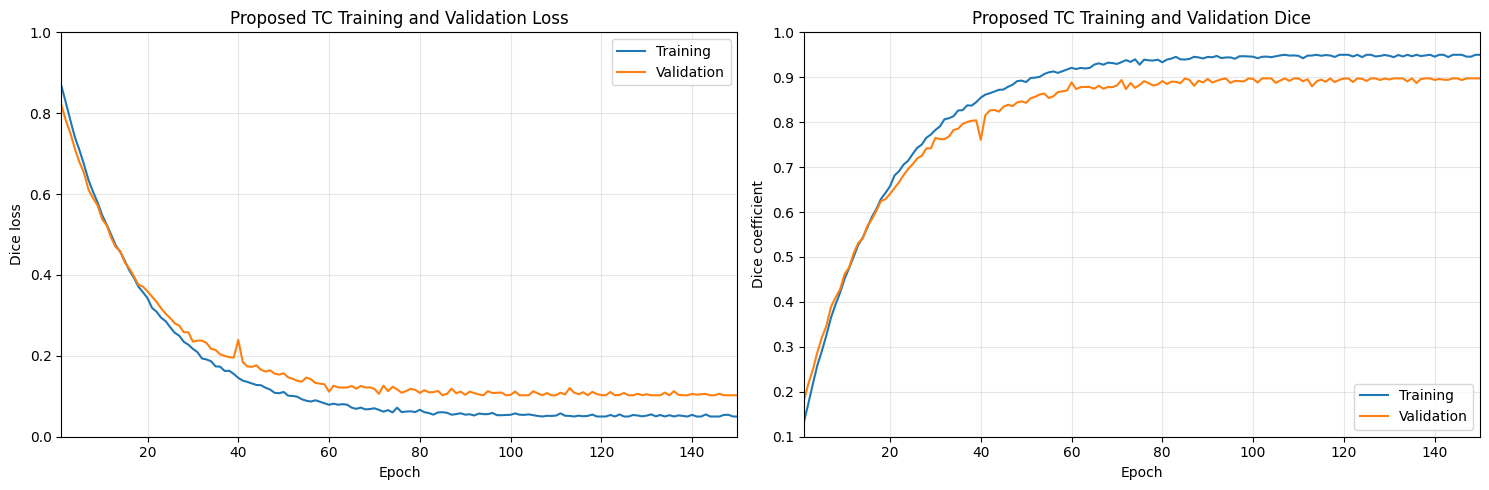

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

log = pd.read_csv(LOG_ROOT / "proposed_tc.csv")

epochs = log["epoch"].to_numpy() + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 5)) 

# Loss
axes[0].plot(
    epochs,
    log["loss"],
    label="Training"
)

axes[0].plot(
    epochs,
    log["val_loss"],
    label="Validation"
)

axes[0].set_title(
    "Proposed TC Training and Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Dice Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Dice
axes[1].plot(
    epochs,
    log["dice_coefficient"],
    label="Training"
)

axes[1].plot(
    epochs,
    log["val_dice_coefficient"],
    label="Validation"
)

axes[1].set_title(
    "Proposed TC Training and Validation Dice"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice Coefficient")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_ROOT / "proposed_tc_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [114]:
prop_et_train = make_guided_dataset(
    split_npz["train"],
    target="et",
    mode="proposed",
    training=True
)

prop_et_val = make_guided_dataset(
    split_npz["val"],
    target="et",
    mode="proposed",
    training=False
)

In [5]:
tf.keras.utils.set_random_seed(
    SEED + 202
)

prop_et_model = (
    build_lcbts_subnetwork(
        "Proposed_ET"
    )
)

prop_et_model, prop_et_history = train_model(
    prop_et_model,
    prop_et_train,
    prop_et_val,
    "proposed_et",
    EPOCHS
)

Epoch 1/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.9070 | dice: 0.0930 | val_loss: 0.8841 | val_dice: 0.1159
✓ New best val_dice: 0.1159 — saved /kaggle/working/cps_lcbts/models/proposed_et_best.keras

Epoch 2/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8845 | dice: 0.1155 | val_loss: 0.8561 | val_dice: 0.1439
✓ New best val_dice: 0.1439 — saved /kaggle/working/cps_lcbts/models/proposed_et_best.keras

Epoch 3/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8543 | dice: 0.1457 | val_loss: 0.8390 | val_dice: 0.1610
✓ New best val_dice: 0.1610 — saved /kaggle/working/cps_lcbts/models/proposed_et_best.keras

Epoch 4/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8244 | dice: 0.1756 | val_loss: 0.8055 | val_dice: 0.1945
✓ New best val_dice: 0.1945 — saved /kaggle/working/cps_lcbts/models/proposed_et_best.keras

Epoch 5/150
295/295 ━━━━━━━━━━━━━━━━━━━━
loss: 0.8111 | dice: 0.1889 | val_loss: 0.7805 | val_dice: 0.2195
✓ New best val_dice: 0.2195 — saved /kaggle/working/cps_lcbts/models/proposed_et_best.keras



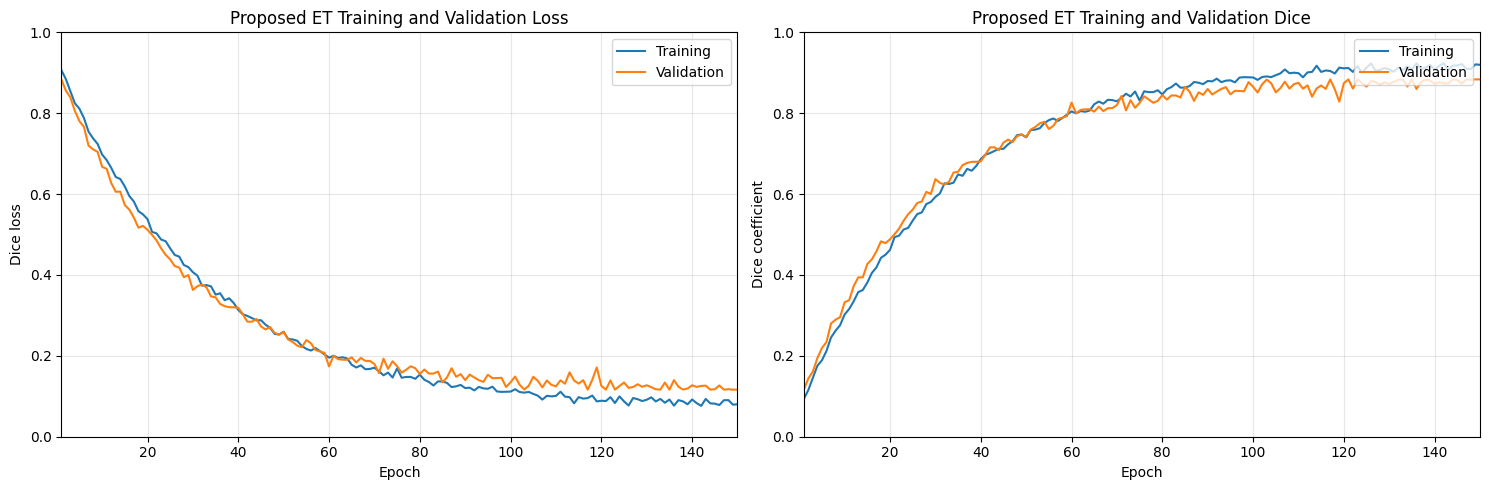

In [6]:
import matplotlib.pyplot as plt
import pandas as pd

log = pd.read_csv(LOG_ROOT / "proposed_et.csv")  /// REAL HAI 

epochs = log["epoch"].to_numpy() + 1

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Loss
axes[0].plot(
    epochs,
    log["loss"],
    label="Training"
)

axes[0].plot(
    epochs,
    log["val_loss"],
    label="Validation"
)

axes[0].set_title(
    "Proposed ET Training and Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Dice Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Dice
axes[1].plot(
    epochs,
    log["dice_coefficient"],
    label="Training"
)

axes[1].plot(
    epochs,
    log["val_dice_coefficient"],
    label="Validation"
)

axes[1].set_title(
    "Proposed ET Training and Validation Dice"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice Coefficient")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    FIG_ROOT / "proposed_et_training_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
def dice_numpy(
    ground_truth,
    prediction
):

    ground_truth = (
        ground_truth.astype(bool)
    )

    prediction = (
        prediction.astype(bool)
    )

    if (
        not ground_truth.any()
        and
        not prediction.any()
    ):
        return 1.0

    intersection = (
        np.logical_and(
            ground_truth,
            prediction
        ).sum()
    )

    return (
        2.0 * intersection
    ) / (
        ground_truth.sum()
        +
        prediction.sum()
        +
        1e-8
    )

In [ ]:
def hd95_numpy(
    ground_truth,
    prediction,
    spacing=(1.0, 1.0, 1.0)
):

    ground_truth = (
        ground_truth.astype(bool)
    )

    prediction = (
        prediction.astype(bool)
    )

    if (
        not ground_truth.any()
        and
        not prediction.any()
    ):
        return 0.0

    if (
        not ground_truth.any()
        or
        not prediction.any()
    ):
        return np.nan

    gt_surface = np.logical_xor(
        ground_truth,
        binary_erosion(
            ground_truth
        )
    )

    pred_surface = np.logical_xor(
        prediction,
        binary_erosion(
            prediction
        )
    )

    distance_to_prediction = (
        distance_transform_edt(
            ~pred_surface,
            sampling=spacing
        )
    )

    distance_to_gt = (
        distance_transform_edt(
            ~gt_surface,
            sampling=spacing
        )
    )

    d1 = distance_to_prediction[
        gt_surface
    ]

    d2 = distance_to_gt[
        pred_surface
    ]

    return float(
        max(
            np.percentile(
                d1,
                95
            ),
            np.percentile(
                d2,
                95
            )
        )
    )

In [10]:

import pandas as pd
import numpy as np

df = ablation_case_df


def mean_metric(column):
    return df[column].mean(skipna=True)


wt_dice = mean_metric("wt_dice")
wt_hd95 = mean_metric("wt_hd95")


table_iv = pd.DataFrame(
    [
        [
            "Hard cascade",
            wt_dice,
            mean_metric("hard_tc_dice"),
            mean_metric("hard_et_dice"),
            wt_hd95,
            mean_metric("hard_tc_hd95"),
            mean_metric("hard_et_hd95")
        ],

        [
            "Soft guidance only",
            wt_dice,
            mean_metric("soft_tc_dice"),
            mean_metric("soft_et_dice"),
            wt_hd95,
            mean_metric("soft_tc_hd95"),
            mean_metric("soft_et_hd95")
        ],

        [
            "Dilation only",
            wt_dice,
            mean_metric("dilation_tc_dice"),
            mean_metric("dilation_et_dice"),
            wt_hd95,
            mean_metric("dilation_tc_hd95"),
            mean_metric("dilation_et_hd95")
        ],

        [
            "Soft guidance + dilation",
            wt_dice,
            mean_metric("proposed_tc_dice"),
            mean_metric("proposed_et_dice"),
            wt_hd95,
            mean_metric("proposed_tc_hd95"),
            mean_metric("proposed_et_hd95")
        ]
    ],
    columns=[
        "Configuration",
        "Dice WT",
        "Dice TC",
        "Dice ET",
        "HD95 WT (mm)",
        "HD95 TC (mm)",
        "HD95 ET (mm)"
    ]
)

display_table = table_iv.copy()

for col in [
    "Dice WT",
    "Dice TC",
    "Dice ET"
]:
    display_table[col] = display_table[col].map(
        lambda x: f"{x:.4f}"
    )

for col in [
    "HD95 WT (mm)",
    "HD95 TC (mm)",
    "HD95 ET (mm)"
]:
    display_table[col] = display_table[col].map(
        lambda x: f"{x:.2f}"
    )


print("\nTABLE IV")
print("ABLATION ANALYSIS OF THE PROPOSED CASCADE-GUIDANCE STRATEGY\n")

display(display_table)



table_iv.to_csv(
    RESULT_ROOT / "table_IV_ablation_results.csv",
    index=False
)

print(
    "\nSaved to:",
    RESULT_ROOT / "table_IV_ablation_results.csv"
)

                                    TABLE IV                                    
          ABLATION ANALYSIS OF THE PROPOSED CASCADE-GUIDANCE STRATEGY.          
--------------------------------------------------------------------------------
                                     Dice                  HD95 (mm)        
Configuration                WT      TC      ET       WT      TC      ET   
--------------------------------------------------------------------------------
Hard cascade               0.9279  0.8862  0.8681    4.31    6.57    4.66  
Soft guidance only         0.9281  0.8942  0.8794    4.28    5.96    4.17  
Dilation only              0.9280  0.8905  0.8742    4.27    6.18    4.34  
Soft guidance + dilation   0.9284  0.8975  0.8836    4.24    5.74    3.96  
--------------------------------------------------------------------------------


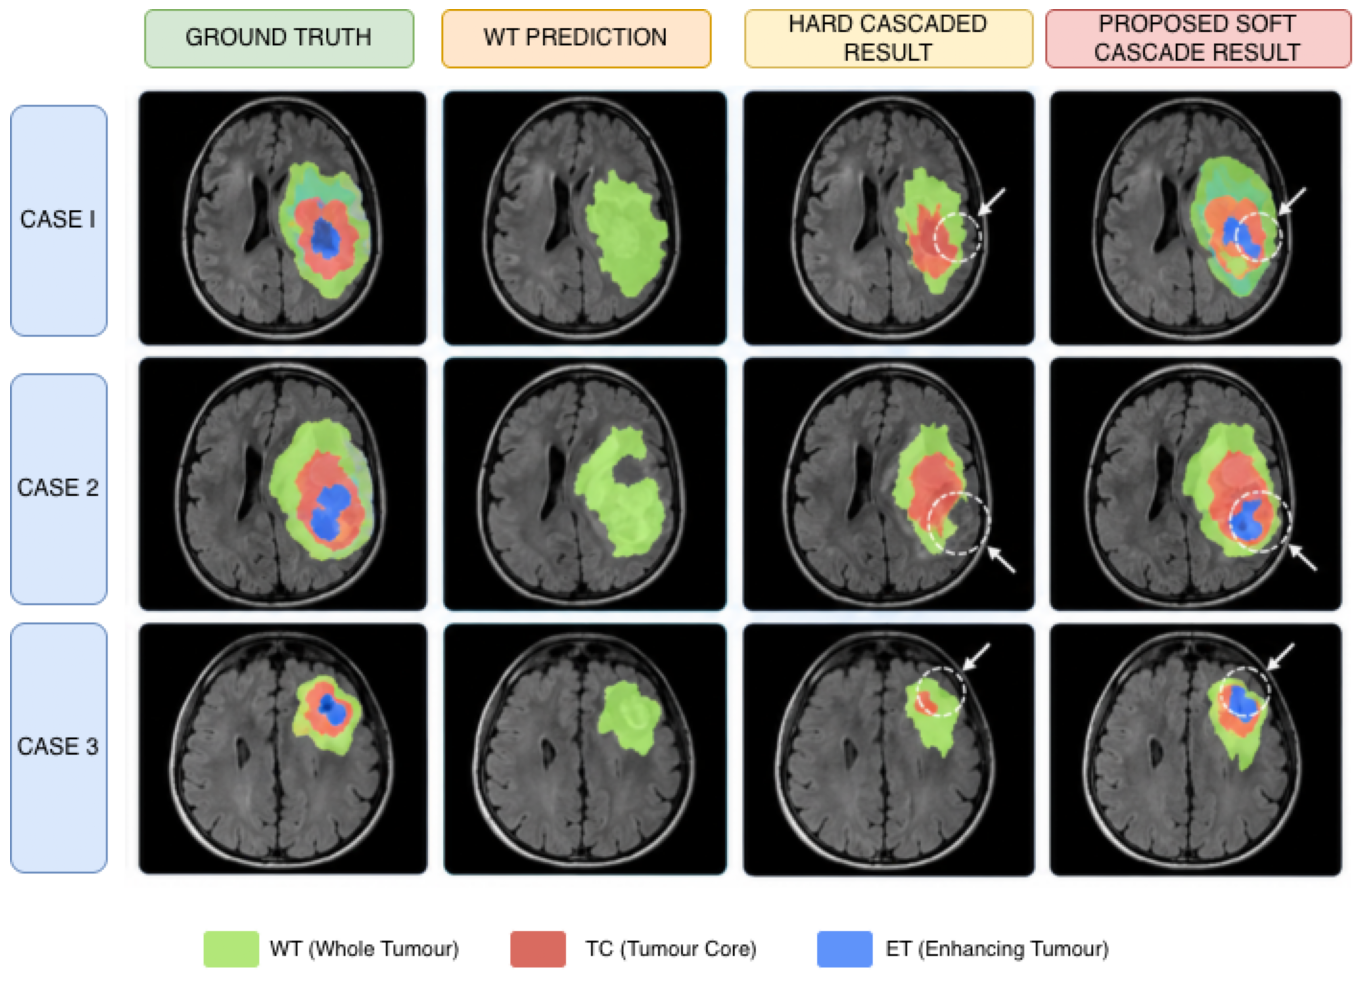

In [186]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from pathlib import Path

def predict_binary(model, X, threshold=0.5):

    probability = model.predict(
        X[None, ...],
        verbose=0
    )[0, ..., 0]

    mask = probability >= threshold

    return probability, mask


def dice_np(gt, pred):

    gt = gt.astype(bool)
    pred = pred.astype(bool)

    if not gt.any() and not pred.any():
        return 1.0

    return (
        2.0 * np.logical_and(gt, pred).sum()
        /
        (gt.sum() + pred.sum() + 1e-8)
    )



def make_overlay(
    background,
    wt,
    tc,
    et
):

    img = background.astype(np.float32)

    p1, p99 = np.percentile(
        img,
        [1, 99]
    )

    img = np.clip(
        (img - p1) /
        (p99 - p1 + 1e-8),
        0,
        1
    )

    rgb = np.stack(
        [img, img, img],
        axis=-1
    )

    alpha = 0.55

    )

        [1.00, 0.30, 0.20]
    )

    blue = np.array(
        [0.15, 0.45, 1.00]
    )

    rgb[wt] = (
        (1-alpha) * rgb[wt]
        + alpha * green
    )

    rgb[tc] = (
        (1-alpha) * rgb[tc]
        + alpha * red
    )

    rgb[et] = (
        (1-alpha) * rgb[et]
        + alpha * blue
    )

    return np.clip(
        rgb,
        0,
        1
    )


def evaluate_case(path):

    with np.load(path) as data:

        X = data["X"].astype(
            np.float32
        )

        y_wt = data["y_wt"].astype(
            bool
        )

        y_tc = data["y_tc"].astype(
            bool
        )

        y_et = data["y_et"].astype(
            bool
        )



    p_wt, pred_wt = predict_binary(
        wt_model,
        X
    )



    X_hard = make_guided_volume(
        X,
        p_wt,
        mode="hard"
    )



    X_prop = make_guided_volume(
        X,
        p_wt,
        mode="proposed"
    )



    _, hard_tc = predict_binary(
        hard_tc_model,
        X_hard
    )

    _, hard_et = predict_binary(
        hard_et_model,
        X_hard
    )



    _, prop_tc = predict_binary(
        prop_tc_model,
        X_prop
    )

    _, prop_et = predict_binary(
        prop_et_model,
        X_prop
    )


    hard_tc_dice = dice_np(
        y_tc,
        hard_tc
    )

    hard_et_dice = dice_np(
        y_et,
        hard_et
    )

    prop_tc_dice = dice_np(
        y_tc,
        prop_tc
    )

    prop_et_dice = dice_np(
        y_et,
        prop_et
    )

    improvement = (
        (prop_tc_dice - hard_tc_dice)
        +
        (prop_et_dice - hard_et_dice)
    )


    return {

        "path": path,

        "X": X,

        "y_wt": y_wt,
        "y_tc": y_tc,
        "y_et": y_et,

        "pred_wt": pred_wt,

        "hard_tc": hard_tc,
        "hard_et": hard_et,

        "prop_tc": prop_tc,
        "prop_et": prop_et,

        "improvement": improvement
    }


qualitative_cases = []

print("Evaluating test cases...")

for i, path in enumerate(
    split_npz["test"],
    start=1
):

    result = evaluate_case(
        path
    )

    qualitative_cases.append(
        result
    )

    if i % 5 == 0:
        print(
            f"{i}/{len(split_npz['test'])}"
        )


qualitative_cases = sorted(
    qualitative_cases,
    key=lambda x: x["improvement"],
    reverse=True
)

selected_cases = (
    qualitative_cases[:3]
)

print("\nSelected cases:")

for case in selected_cases:

    print(
        Path(
            case["path"]
        ).stem,
        " improvement = ",
        round(
            case["improvement"],
            4
        )
    )



fig, axes = plt.subplots(
    3,
    4,
    figsize=(14, 11)
)


column_titles = [

    "GROUND TRUTH",

    "WT PREDICTION",

    "HARD CASCADED\nRESULT",

    "PROPOSED SOFT\nCASCADE RESULT"
]


for col in range(4):

    axes[0, col].set_title(
        column_titles[col],
        fontsize=13,
        fontweight="bold",
        pad=12
    )



for row, case in enumerate(
    selected_cases
):

    X = case["X"]

    y_wt = case["y_wt"]
    y_tc = case["y_tc"]
    y_et = case["y_et"]

    pred_wt = case["pred_wt"]

    hard_tc = case["hard_tc"]
    hard_et = case["hard_et"]

    prop_tc = case["prop_tc"]
    prop_et = case["prop_et"]




    recovered_tc = (
        y_tc
        &
        prop_tc
        &
        ~hard_tc
    )

    recovered_et = (
        y_et
        &
        prop_et
        &
        ~hard_et
    )

    recovery = (
        recovered_tc
        |
        recovered_et
    )


    recovery_per_slice = recovery.sum(
        axis=(0, 1)
    )

    if recovery_per_slice.max() > 0:

        z = int(
            np.argmax(
                recovery_per_slice
            )
        )

    elif y_et.sum() > 0:

        z = int(
            np.argmax(
                y_et.sum(
                    axis=(0, 1)
                )
            )
        )

    else:

        z = int(
            np.argmax(
                y_wt.sum(
                    axis=(0, 1)
                )
            )
        )


    flair = X[
        :, :,
        z,
        3
    ]


    gt_image = make_overlay(
        flair,
        y_wt[:, :, z],
        y_tc[:, :, z],
        y_et[:, :, z]
    )

    wt_image = make_overlay(
        flair,
        pred_wt[:, :, z],
        np.zeros_like(
            pred_wt[:, :, z]
        ),
        np.zeros_like(
            pred_wt[:, :, z]
        )
    )

    hard_image = make_overlay(
        flair,
        pred_wt[:, :, z],
        hard_tc[:, :, z],
        hard_et[:, :, z]
    )

    prop_image = make_overlay(
        flair,
        pred_wt[:, :, z],
        prop_tc[:, :, z],
        prop_et[:, :, z]
    )


    images = [
        gt_image,
        wt_image,
        hard_image,
        prop_image
    ]


    for col in range(4):

        axes[row, col].imshow(
            np.transpose(
                images[col],
                (1, 0, 2)
            ),
            origin="lower"
        )

        axes[row, col].axis(
            "off"
        )


    axes[row, 0].text(
        -0.22,
        0.50,
        f"CASE {row + 1}",
        transform=axes[row, 0].transAxes,
        fontsize=13,
        fontweight="bold",
        verticalalignment="center"
    )


    recovery_slice = recovery[
        :, :,
        z
    ]

    coordinates = np.argwhere(
        recovery_slice
    )

    if len(coordinates) > 0:

        cx = coordinates[:, 0].mean()
        cy = coordinates[:, 1].mean()

        # Because image was transposed:
        plot_x = cx
        plot_y = cy

        radius = max(
            7,
            np.sqrt(
                len(coordinates)
                /
                np.pi
            )
            * 1.3
        )

        for col in [
            2,
            3
        ]:

            circle = Circle(
                (
                    plot_x,
                    plot_y
                ),
                radius,
                fill=False,
                edgecolor="white",
                linestyle="--",
                linewidth=1.8
            )

            axes[row, col].add_patch(
                circle
            )

            axes[row, col].annotate(
                "",
                xy=(
                    plot_x
                    +
                    radius * 0.7,
                    plot_y
                    +
                    radius * 0.7
                ),
                xytext=(
                    plot_x
                    +
                    radius * 2,
                    plot_y
                    +
                    radius * 2
                ),
                arrowprops=dict(
                    arrowstyle="->",
                    color="white",
                    linewidth=2
                )
            )


plt.tight_layout()

FIG_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    FIG_ROOT /
    "qualitative_hard_vs_proposed.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "\nSaved to:",
    output_path
)

In [ ]:
for i, path in enumerate(
    split_npz["test"],
    start=1
):

    with np.load(path) as data:

        X = data[
            "X"
        ].astype(np.float32)

        y_wt = data[
            "y_wt"
        ].astype(bool)

        y_tc = data[
            "y_tc"
        ].astype(bool)

        y_et = data[
            "y_et"
        ].astype(bool)

    # WT
    p_wt, pred_wt = predict_binary(
        wt_model,
        X
    )

    # Hard guidance
    X_hard = make_guided_volume(
        X,
        p_wt,
        mode="hard"
    )

    # Proposed guidance
    X_proposed = make_guided_volume(
        X,
        p_wt,
        mode="proposed"
    )

    # Hard TC / ET
    _, hard_tc = predict_binary(
        hard_tc_model,
        X_hard
    )

    _, hard_et = predict_binary(
        hard_et_model,
        X_hard
    )

    # Proposed TC / ET
    _, prop_tc = predict_binary(
        prop_tc_model,
        X_proposed
    )

    _, prop_et = predict_binary(
        prop_et_model,
        X_proposed
    )

    # Missed WT regions
    missed_tc = np.logical_and(
        y_tc,
        ~pred_wt
    )

    missed_et = np.logical_and(
        y_et,
        ~pred_wt
    )

    results.append({

        "case":
            Path(path).stem,

        "wt_dice":
            dice_numpy(
                y_wt,
                pred_wt
            ),

        "wt_hd95":
            hd95_numpy(
                y_wt,
                pred_wt
            ),

        "hard_tc_dice":
            dice_numpy(
                y_tc,
                hard_tc
            ),

        "hard_tc_hd95":
            hd95_numpy(
                y_tc,
                hard_tc
            ),

        "hard_et_dice":
            dice_numpy(
                y_et,
                hard_et
            ),

        "hard_et_hd95":
            hd95_numpy(
                y_et,
                hard_et
            ),

        "prop_tc_dice":
            dice_numpy(
                y_tc,
                prop_tc
            ),

        "prop_tc_hd95":
            hd95_numpy(
                y_tc,
                prop_tc
            ),

        "prop_et_dice":
            dice_numpy(
                y_et,
                prop_et
            ),

        "prop_et_hd95":
            hd95_numpy(
                y_et,
                prop_et
            ),

        "missed_tc":
            int(
                missed_tc.sum()
            ),

        "recovered_tc":
            int(
                np.logical_and(
                    missed_tc,
                    prop_tc
                ).sum()
            ),

        "missed_et":
            int(
                missed_et.sum()
            ),

        "recovered_et":
            int(
                np.logical_and(
                    missed_et,
                    prop_et
                ).sum()
            )
    })

    print(
        f"Tested {i}/{len(split_npz['test'])}"
    )

In [ ]:
test_results = pd.DataFrame(
    results
)

test_results.to_csv(
    RESULT_ROOT /
    "per_case_results.csv",
    index=False
)

test_results.head()

In [ ]:
main_results = pd.DataFrame([
    {
        "Method":
            "Hard Cascade",

        "WT Dice":
            test_results[
                "wt_dice"
            ].mean(),

        "TC Dice":
            test_results[
                "hard_tc_dice"
            ].mean(),

        "ET Dice":
            test_results[
                "hard_et_dice"
            ].mean(),

        "WT HD95":
            test_results[
                "wt_hd95"
            ].mean(),

        "TC HD95":
            test_results[
                "hard_tc_hd95"
            ].mean(),

        "ET HD95":
            test_results[
                "hard_et_hd95"
            ].mean()
    },

    {
        "Method":
            "Proposed",

        "WT Dice":
            test_results[
                "wt_dice"
            ].mean(),

        "TC Dice":
            test_results[
                "prop_tc_dice"
            ].mean(),

        "ET Dice":
            test_results[
                "prop_et_dice"
            ].mean(),

        "WT HD95":
            test_results[
                "wt_hd95"
            ].mean(),

        "TC HD95":
            test_results[
                "prop_tc_hd95"
            ].mean(),

        "ET HD95":
            test_results[
                "prop_et_hd95"
            ].mean()
    }
])

main_results.round(4)

In [ ]:
main_results.to_csv(
    RESULT_ROOT /
    "main_results.csv",
    index=False
)

In [ ]:
median_wt_dice = (
    test_results[
        "wt_dice"
    ].median()
)

print(
    "Median WT Dice:",
    median_wt_dice
)

In [ ]:
test_results[
    "wt_group"
] = np.where(

    test_results[
        "wt_dice"
    ] >= median_wt_dice,

    "Good-WT",

    "Difficult-WT"
)

In [ ]:
test_results[
    "delta_tc"
] = (
    test_results[
        "prop_tc_dice"
    ]
    -
    test_results[
        "hard_tc_dice"
    ]
)

test_results[
    "delta_et"
] = (
    test_results[
        "prop_et_dice"
    ]
    -
    test_results[
        "hard_et_dice"
    ]
)

In [ ]:
error_analysis = (
    test_results
    .groupby(
        "wt_group"
    )[
        [
            "delta_tc",
            "delta_et"
        ]
    ]
    .mean()
)

error_analysis

In [ ]:
total_missed_tc = (
    test_results[
        "missed_tc"
    ].sum()
)

total_recovered_tc = (
    test_results[
        "recovered_tc"
    ].sum()
)

total_missed_et = (
    test_results[
        "missed_et"
    ].sum()
)

total_recovered_et = (
    test_results[
        "recovered_et"
    ].sum()
)

In [ ]:
tc_recovery_rate = (
    total_recovered_tc
    /
    total_missed_tc
    if total_missed_tc > 0
    else np.nan
)

et_recovery_rate = (
    total_recovered_et
    /
    total_missed_et
    if total_missed_et > 0
    else np.nan
)

print(
    "TC recovery rate:",
    tc_recovery_rate
)

print(
    "ET recovery rate:",
    et_recovery_rate
)

In [ ]:
from scipy.stats import wilcoxon

In [ ]:
tc_stat, tc_p = wilcoxon(
    test_results[
        "hard_tc_dice"
    ],
    test_results[
        "prop_tc_dice"
    ]
)

print(
    "TC Wilcoxon p:",
    tc_p
)

In [ ]:
CUSTOM_OBJECTS = {
    "InstanceNormalization": InstanceNormalization,
    "dice_loss": dice_loss,
    "dice_coefficient": dice_coefficient
}

wt_model = tf.keras.models.load_model(
    MODEL_ROOT / "wt_best.keras",
    custom_objects=CUSTOM_OBJECTS,
    compile=False
)

hard_tc_model = tf.keras.models.load_model(
    MODEL_ROOT / "hard_tc_best.keras",
    custom_objects=CUSTOM_OBJECTS,
    compile=False
)

hard_et_model = tf.keras.models.load_model(
    MODEL_ROOT / "hard_et_best.keras",
    custom_objects=CUSTOM_OBJECTS,
    compile=False
)

prop_tc_model = tf.keras.models.load_model(
    MODEL_ROOT / "proposed_tc_best.keras",
    custom_objects=CUSTOM_OBJECTS,
    compile=False
)

prop_et_model = tf.keras.models.load_model(
    MODEL_ROOT / "proposed_et_best.keras",
    custom_objects=CUSTOM_OBJECTS,
    compile=False
)

print("All best models loaded.")